# Optimal transport: feasibility before cost

Finite balanced transport with cost C_ij=(x_i-y_j)^2. Compare direct Sinkhorn, log-domain Sinkhorn and unregularized HiGHS LP. An independent 1D weighted monotone coupling verifies LP costs. Rounding repairs feasibility, not entropy bias or optimality. Numerical primal-dual bounds are checked with float64 tolerances; they are not interval-arithmetic certificates.

In [1]:
import json
from pathlib import Path
r=json.loads(Path('benchmarks/results.json').read_text())
print('Predeclared gate:',r['success'])
print('Checks:',r['checks'])
print('Summary:',r['summary'])

Predeclared gate: True
Checks: {'log_all_finite': True, 'max_rounded_residual': 4.527628272299467e-16, 'max_reference_discrepancy': 5.551115123125783e-16, 'max_scaled_bound_violation': 0.0, 'max_separated_relative_cost_error': 5.940299556073114e-06, 'naive_failed_all_selected': True, 'false_low_cost_detected': True}
Summary: [{'method': 'naive', 'total': 36, 'failed': 6, 'nonconverged': 0, 'max_raw_residual': 9.960410968234967e-10, 'max_rounded_residual': 4.501607420159814e-16}, {'method': 'log', 'total': 36, 'failed': 0, 'nonconverged': 1, 'max_raw_residual': 0.00024523353173425133, 'max_rounded_residual': 4.527628272299467e-16}]


In [2]:
print('Two-atom adversarial experiment:')
for name,value in r['adversarial'].items():
    print(name,value)
assert r['adversarial']['raw_residual']>1
assert abs(r['adversarial']['rounded_cost']-.8)<1e-12

Two-atom adversarial experiment:
reference 0.8
raw_cost 3.0173949583280115e-43
rounded_cost 0.8000000000000002
raw_residual 1.6000000000000003
rounded_residual 2.220446049250313e-16
lower 0.014326966884775272
converged False
raw_plan [[0.10000000000000002, 3.0132615405768774e-43], [4.133417751134321e-46, 0.8999999999999999]]
rounded_plan [[0.1, 0.8000000000000002], [4.592686390149246e-47, 0.1]]


In [3]:
print('n=64, epsilon=.005:')
for row in r['selected']:
    print(row['scenario'],row['method'],'failure:',row['failed'],'LP:',row['reference'],'repaired cost:',row['upper'],'converged:',row['converged'])

n=64, epsilon=.005:
overlap naive failure: False LP: 0.0867507413565811 repaired cost: 0.08886677751259546 converged: True
overlap log failure: False LP: 0.0867507413565811 repaired cost: 0.08886677751259546 converged: True
separated naive failure: True LP: 400.0 repaired cost: None converged: False
separated log failure: False LP: 400.0 repaired cost: 400.00237611982243 converged: True
mass_mismatch naive failure: False LP: 0.8650877635004611 repaired cost: 0.8650883560992482 converged: True
mass_mismatch log failure: False LP: 0.8650877635004611 repaired cost: 0.8650883560992483 converged: True


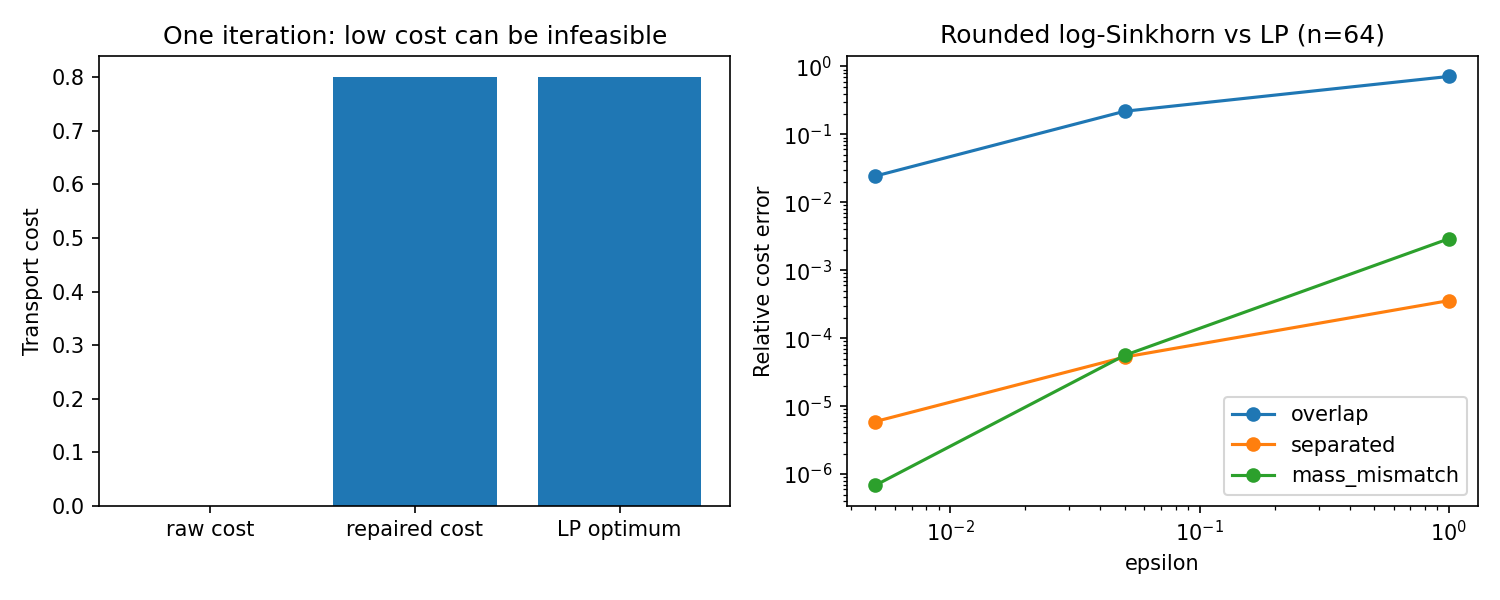

In [4]:
from IPython.display import Image,display
display(Image(filename='benchmarks/audit.png'))

## Conclusions

A near-zero cost may be infeasible and is not evidence of an improved transport solver. Log-domain updates avoid the observed kernel underflow, but do not ensure fast convergence. Feasible rounding gives an upper bound, not the exact optimum; entropy and early-stopping errors remain. One-dimensional synthetic cases do not establish multivariate performance or causal distributional dynamics. See informe.md for assumptions, prior art, raw failures and limitations.

## Desarrollo experimental ampliado — 18 de octubre de 2026

Las siguientes celdas recalculan nuevos experimentos desde los modelos e inputs. Los resultados históricos anteriores se conservan como evidencia separada. Cada experimento declara su alcance; no eleva automáticamente la madurez del proyecto.

### 1. Problema, cota dual y error de regularización
El transporte discreto minimiza $\langle C,P\rangle$ sujeto a $P\mathbf1=a$, $P^T\mathbf1=b$ y $P\geq0$. Un par dual factible satisface $f_i+g_j\leq C_{ij}$ y produce una cota inferior $a^Tf+b^Tg$. Una reparación factible produce una cota superior. El intervalo entre ambas mide incertidumbre numérica sobre el óptimo LP; no es un intervalo estadístico.

Separaremos dos ejes: presupuesto de iteraciones y regularización. Una marginal reparada puede ser exacta aunque el costo siga lejos del óptimo.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
from src.transport import sinkhorn,residual
from src.reference import linear_program,monotone_w2_squared
x=np.array([0.,.2,.7,1.]); y=np.array([.1,.4,.8,1.3])
a=np.array([.4,.1,.2,.3]); b=np.array([.1,.4,.4,.1])
cost=(x[:,None]-y[None,:])**2
optimum,plan_lp=linear_program(a,b,cost)
assert abs(optimum-monotone_w2_squared(x,y,a,b))<1e-10
transport_rows=[]
for epsilon in [.001,.01,.1,1.]:
    for budget in [1,10,100,1000]:
        solution=sinkhorn(a,b,cost,epsilon,max_iterations=budget)
        transport_rows.append(dict(epsilon=epsilon,budget=budget,iterations=solution.iterations,
            raw_residual=solution.raw_residual,repaired_residual=solution.rounded_residual,
            lower=solution.lower,upper=solution.upper,gap=solution.upper-solution.lower,
            excess_cost=solution.upper-optimum,converged=solution.converged))
transport_table=pd.DataFrame(transport_rows)
display(transport_table.round(7))
assert transport_table.repaired_residual.max()<1e-12
assert (transport_table.lower<=optimum+1e-9).all()
assert (transport_table.upper>=optimum-1e-9).all()

,epsilon,budget,iterations,raw_residual,repaired_residual,lower,upper,gap,excess_cost,converged
0,0.001,1,1,0.720000,0.0,0.034915,0.104043,0.069129,0.032043,False
1,0.001,10,10,0.600000,0.0,0.042517,0.072000,0.029483,0.000000,False
2,0.001,100,100,0.010299,0.0,0.070299,0.075696,0.005397,0.003696,False
3,0.001,1000,1000,0.000529,0.0,0.070304,0.072190,0.001886,0.000190,False
4,0.010,1,1,0.706066,0.0,0.025248,0.103916,0.078669,0.031916,False
5,0.010,10,10,0.093232,0.0,0.054483,0.105446,0.050963,0.033446,False
6,0.010,100,100,0.005438,0.0,0.055015,0.073955,0.018939,0.001955,False
7,0.010,1000,1000,0.000505,0.0,0.055040,0.072182,0.017142,0.000182,False
8,0.100,1,1,0.308862,0.0,-0.120021,0.147817,0.267838,0.075817,False
9,0.100,10,10,0.032860,0.0,-0.103985,0.093824,0.197809,0.021824,False


### 2. Presupuesto computacional frente a calidad
Comparar costos sólo tiene sentido tras verificar las marginales. Las curvas de gap no se fuerzan a ser monótonas: los potenciales duales factibilizados no son necesariamente las mejores cotas históricas.

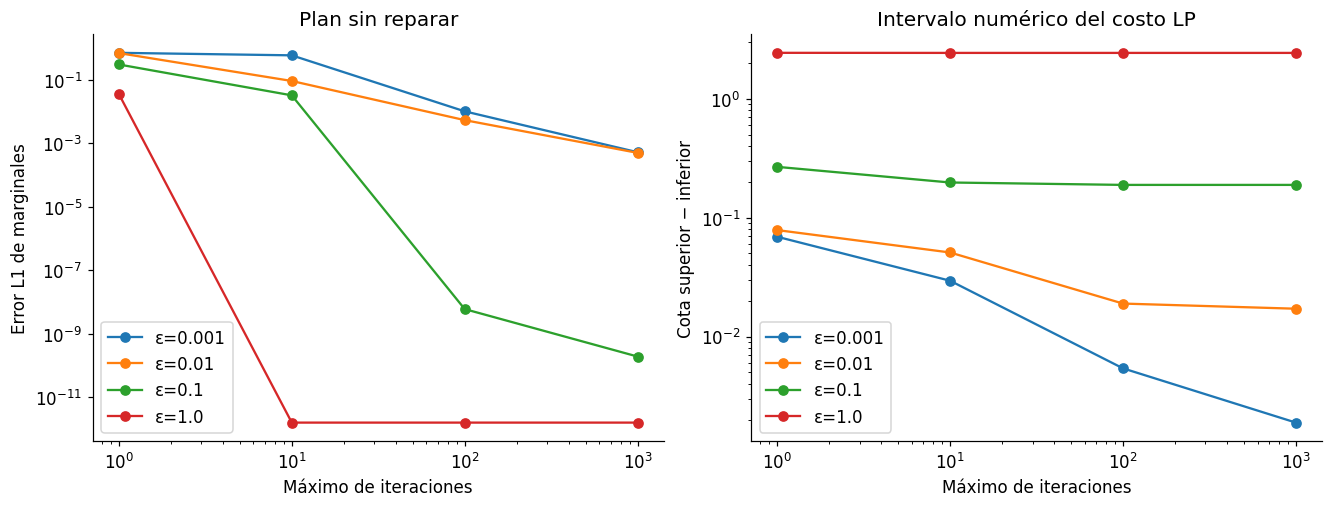

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for epsilon,group in transport_table.groupby('epsilon'):
    axes[0].loglog(group.budget,np.maximum(group.raw_residual,1e-16),'o-',label=f'ε={epsilon}')
    axes[1].loglog(group.budget,np.maximum(group.gap,1e-16),'o-',label=f'ε={epsilon}')
axes[0].set(xlabel='Máximo de iteraciones',ylabel='Error L1 de marginales',title='Plan sin reparar')
axes[1].set(xlabel='Máximo de iteraciones',ylabel='Cota superior − inferior',title='Intervalo numérico del costo LP')
for ax in axes: ax.legend()
plt.show()

### 3. Inspección de planes y cambio de unidades
Un mapa de masa permite distinguir el plan de costo mínimo del plan suavizado. Si las coordenadas se multiplican por s, los costos y epsilon deben multiplicarse por s² para conservar el mismo plan regularizado. Mantener epsilon fijo cambia el problema relativo.

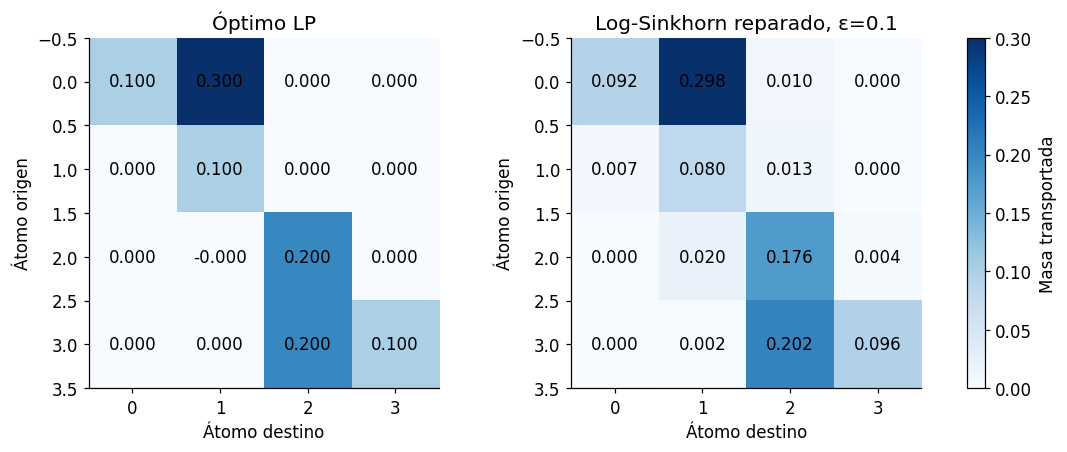

Costo LP: 0.07200000000000002 ; costo suavizado reparado: 0.08516127912199396


In [7]:
smooth=sinkhorn(a,b,cost,.1,max_iterations=2000)
scaled=sinkhorn(a,b,9*cost,.9,max_iterations=2000)
assert np.max(abs(smooth.plan-scaled.plan))<1e-9
assert abs(scaled.upper-9*smooth.upper)<1e-9
fig,axes=plt.subplots(1,2,figsize=(10,4),layout='constrained')
for ax,plan,title in zip(axes,[plan_lp,smooth.plan],['Óptimo LP','Log-Sinkhorn reparado, ε=0.1']):
    im=ax.imshow(plan,vmin=0,vmax=max(plan_lp.max(),smooth.plan.max()),cmap='Blues')
    ax.set(title=title,xlabel='Átomo destino',ylabel='Átomo origen')
    for i,j in np.ndindex(plan.shape): ax.text(j,i,f'{plan[i,j]:.3f}',ha='center',va='center')
fig.colorbar(im,ax=axes,label='Masa transportada'); plt.show()
print('Costo LP:',optimum,'; costo suavizado reparado:',smooth.upper)

### 4. Alcance del nuevo experimento
El barrido recalcula 16 configuraciones en un soporte ponderado pequeño. Las cotas contrastan con un LP y una referencia monótona independiente de dimensión uno. No establecen escalabilidad de alta dimensión. Una masa reparada tampoco identifica dinámica causal entre distribuciones. Para uso aplicado harían falta métricas del dominio, evaluación de soporte, memoria n×m y calibración de epsilon.

### Lectura de los resultados ejecutados

El LP obtiene **0.072000** y el plan reparado con ε=0.1 obtiene **0.0851613**, aproximadamente **18.28%** más. El barrido muestra que corregir marginales y aumentar iteraciones no elimina necesariamente el sesgo de regularización. El mapa de masas permite localizar la dispersión adicional del plan suavizado.